# Dong 2020 Prostate — 04 Expression (EMT-TF overlay)
The EMT-TF step is **unconditional** and is the final notebook. Because Gate 2 = GO (non-branching) / Gate 3 = NA, the branching-only correlation/modules notebooks are not produced, so the expression step is numbered **04**.

**Panel design (reference style):** a categorical overlay of **thresholded expressers** on a grey manifold (not a continuous single-gene colormap). Candidates are drawn from the Snail/Zeb/Twist families **plus** other mesenchymal TF families (FOXC1/2, PRRX1/2, SOX9), **detection-gated** on this dataset; **VIM is excluded** (mesenchymal marker, not a transcription factor). Display thresholds are set among expressers so the overlay is not outlier-washed.

In [1]:
import os
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
pth     = os.path.join('..', '..', '..', '..')
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', 'Prostate', name)
pth_out = os.path.join(pth, 'figures', 'mesencontext', 'claude', 'Prostate', name)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad')); adata

AnnData object with n_obs × n_vars = 8281 × 15672
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', 'compartment', 'GSE162534', 'GSE229103', 'rRNAModifications', 'Gast', 'pSom', 'Crest', 'AR_luminal', 'NE_program', 'lineage', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'celltype_colors', 'compartment_colors', 'diffmap_evals', 'graph', 'leiden', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'phase_colors', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_diffmap', 'X_pca', 'X_pca_harmony', 'X_umap', 'harm_th0', 'harm_th10', 'harm_th2', 'harm_th5'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Detection-gate the EMT-TF panel (>=3% expressers) and rank by pseudotime trend
By raw pseudotime trend the strongest early/root candidates are **ASCL1** (rho=-0.25) and **SOX2** (rho=-0.17) - but these are **neuroendocrine-lineage/identity** transcription factors (the NE program mapped in 01), **not canonical EMT-TFs**, so they are deliberately excluded from the EMT panel (as are the near-ubiquitous SOX4/TBX3/TCF3). Among *bona fide* EMT / mesenchymal TFs, the cleanest detection-gated early->late pair is **SOX9** (root/Gast-pSom end; rho=-0.12, 23.8% detection - a neural-crest/EMT TF) -> **TWIST1** (terminus/Crest end; rho=+0.08, 27.2%). The printout below lists the full canonical-EMT-TF panel ranked by pseudotime; ASCL1/SOX2 are intentionally absent from it because they are lineage, not EMT, factors.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2','SOX9']
panel = [g for g in panel if g in adata.var_names]
X = pd.DataFrame(adata[:, panel].X.toarray(), columns=panel, index=adata.obs_names)
tab = pd.DataFrame({'pct_expr': (X>0).mean().mul(100).round(1),
                    'rho_pt'  : {g: round(spearmanr(adata.obs.t, X[g])[0], 3) for g in panel}})
tab = tab[tab.pct_expr >= 3].sort_values('rho_pt')
print(tab)

        pct_expr  rho_pt
SOX9        23.8  -0.116
SNAI1        4.6  -0.101
FOXC1        3.2  -0.096
TWIST2       3.3  -0.080
PRRX2        3.4  -0.035
TWIST1      27.2   0.080


In [5]:
# display thresholds = median among expressers (avoids outlier-washing)
g_plt = {}
for g, c in [('SOX9', 'tab:blue'), ('TWIST1', 'tab:red')]:
    v = adata[:, g].X.toarray().ravel(); thr = float(np.quantile(v[v>0], 0.5))
    g_plt[g] = (c, thr)
    print(f'{g}: {100*(v>0).mean():.1f}% expr | thr={thr:.2f} | expressers>thr={int((v>thr).sum())} | rho_pt={spearmanr(adata.obs.t, v)[0]:+.2f}')

SOX9: 23.8% expr | thr=0.61 | expressers>thr=985 | rho_pt=-0.12
TWIST1: 27.2% expr | thr=1.10 | expressers>thr=1126 | rho_pt=+0.08


### EMT-TF expression figure — thresholded expressers over a grey manifold

saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Prostate/Dong2020_Prostate-5/expression.pdf


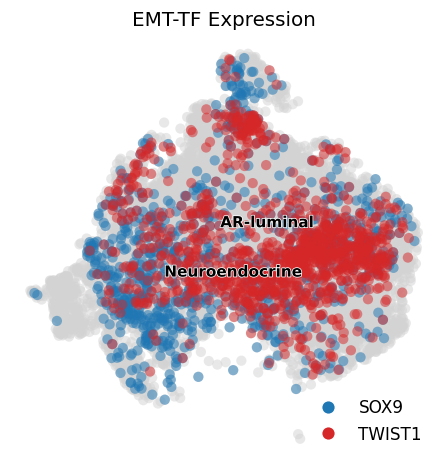

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=180, alpha=.5, frameon=False, show=False, ax=ax)
for var, (c, thresh) in g_plt.items():
    adata_plt = adata[adata[:, var].X.toarray().ravel() > thresh].copy()
    sc.pl.umap(adata_plt, na_color=c, size=180, alpha=.5, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=9, label=v) for v,(c,_) in g_plt.items()]
ax.legend(handles=handles, loc='lower right', frameon=False, fontsize=11)
ax.set_title('EMT-TF Expression', size=13)
fn = os.path.join(pth_out, 'expression.pdf'); plt.savefig(fn, bbox_inches='tight'); plt.show()
print('saved', fn)

**Read.** SOX9 (blue) marks the Gast/pSom-high developmental origin; TWIST1 (red) marks the Crest-high terminus — an early->late EMT-TF hand-off along the single non-branching axis, consistent with the inverse terminal Crest gradient.